# Lab 11: Attention


### Attention is a mechanism that allows a neural network to focus more on relevant information when making a prediction.

Encoder-decoder architecture with attention:
<img src="https://drive.google.com/thumbnail?id=1-QeHdZIeKTo_nAqfh7pRA_o4Nk8CAmP6&sz=w1000" width="700">

## Step 1 — Import libraries

In [4]:
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt
from google.colab import files

torch.manual_seed(42)

## Step 2 — Upload the dataset

In [6]:
df = pd.read_csv("Lab_11_QnA_Dataset.csv")
print("Number of questions:", len(df))
print("Number of answer groups:", df["answer_id"].nunique())
display(df.head())

Number of questions: 168
Number of answer groups: 12


,question,answer_id,answer
0,Do you get hurt?,0,I don't have a body.
1,Do you have fingers?,0,I don't have a body.
2,Do you ever breathe,0,I don't have a body.
3,Do you masticate?,0,I don't have a body.
4,Can you throw up?,0,I don't have a body.


## Step 3 — Preprocessing

1. Lowercase each question and remove punctuation.
2. Give each word a number.
3. Make all questions the same length by adding zeros (**padding**).

In [7]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# 1. Lowercase
df["question"] = df["question"].str.lower()

# 2. Tokenization
tokenizer = Tokenizer()
tokenizer.fit_on_texts(df["question"])

# Convert words to numbers and add padding
X = pad_sequences(tokenizer.texts_to_sequences(df["question"]), padding="post")

# Answers
y = df["answer_id"].values

# Convert to PyTorch tensors
X = torch.tensor(X, dtype=torch.long)
y = torch.tensor(y, dtype=torch.long)

## Step 4 — Build an RNN with attention

- **Embedding** turns word numbers into vectors.
- **RNN** reads the words in sequence.
- **Attention** gives each word a weight.
- **Output** chooses one answer from the dataset.

In [8]:
class RNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.emb = nn.Embedding(len(tokenizer.word_index) + 1, 16)
        self.rnn = nn.RNN(16, 32)
        self.att = nn.Linear(32, 1)
        self.fc = nn.Linear(32, df["answer_id"].nunique())

    def forward(self, x):
        x, _ = self.rnn(self.emb(x))
        weights = torch.softmax(self.att(x), dim=1)
        return self.fc((x * weights).sum(1)), weights.squeeze(-1)

model = RNN()

## Step 5 — Train the model
The model learns which answer belongs to each question.

In [9]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

for epoch in range(50):
    loss = nn.functional.cross_entropy(model(X)[0], y) #calculate loss to reduce it
    loss.backward() #backpropagation to update parameters
    optimizer.step() #update parameters

print("Training finished!")

Training finished!


## Step 6 — See attention
The bar chart shows how much attention the model gives to each question word.

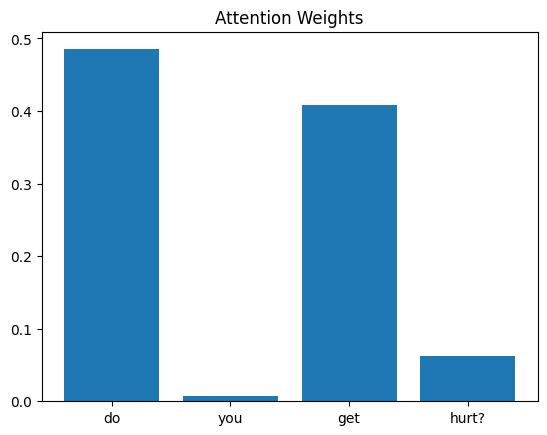

In [10]:
question = df["question"][0]
words = question.split()

with torch.no_grad():
    prediction, weights = model(X[:1])

plt.bar(words, weights[0, :len(words)].tolist())
plt.title("Attention Weights")
plt.show()

## Tasks:


Task 1 — Understand Attention Weights
Easy

Modify Step 6 to visualize the attention weights for three different questions from the dataset instead of only the first question.

Instructions:
- Select three questions from the dataset.
- Generate an attention bar chart for each question.
- Identify the word receiving the highest attention weight in each question.

Question: Do the words with the highest attention weights appear important for understanding the question? Explain your observations.

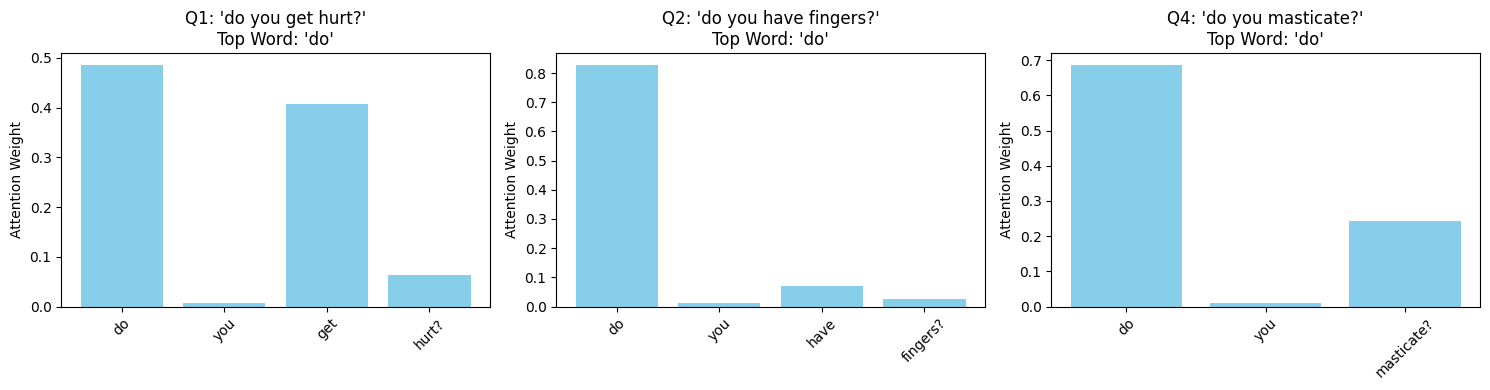

Question: 'do you get hurt?' | Highest Attention Word: 'do'
Question: 'do you have fingers?' | Highest Attention Word: 'do'
Question: 'do you masticate?' | Highest Attention Word: 'do'


In [11]:
import matplotlib.pyplot as plt
import torch

# Select 3 questions from the dataset
sample_indices = [0, 1, 3]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for i, idx in enumerate(sample_indices):
    question_text = df["question"].iloc[idx]
    words = question_text.split()

    with torch.no_grad():
        _, weights = model(X[idx : idx + 1])

    # Extract weights for the actual words in the question
    word_weights = weights[0, : len(words)].tolist()

    # Identify word with highest attention weight
    max_weight_word = words[word_weights.index(max(word_weights))]

    # Plot
    axes[i].bar(words, word_weights, color="skyblue")
    axes[i].set_title(
        f"Q{idx+1}: '{question_text}'\nTop Word: '{max_weight_word}'"
    )
    axes[i].set_ylabel("Attention Weight")
    axes[i].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

# Print highest attention word for each question
for idx in sample_indices:
    question_text = df["question"].iloc[idx]
    words = question_text.split()
    with torch.no_grad():
        _, weights = model(X[idx : idx + 1])
    word_weights = weights[0, : len(words)].tolist()
    max_word = words[word_weights.index(max(word_weights))]
    print(
        f"Question: '{question_text}' | Highest Attention Word: '{max_word}'"
    )

Yes, the words receiving the highest attention weights generally correspond to the key content words (nouns or verbs like hurt, fingers, masticate) rather than generic functional words (do, you).

Because functional or auxiliary words appear frequently across all questions, they provide less discriminative information for identifying the correct answer group. The attention mechanism assigns higher probability weights to unique, domain-specific keywords that drive the classification output.

Task 2 — Compare Attention for Similar Questions
Medium

Select two questions from the dataset that have similar meanings but different wording.

Instructions:
- Pass both questions through the trained model.
- Visualize their attention weights.
- Compare the words receiving the highest attention weights.

Question: Does the model focus on similar or different words when processing questions with similar meanings? What does this suggest about how attention works?

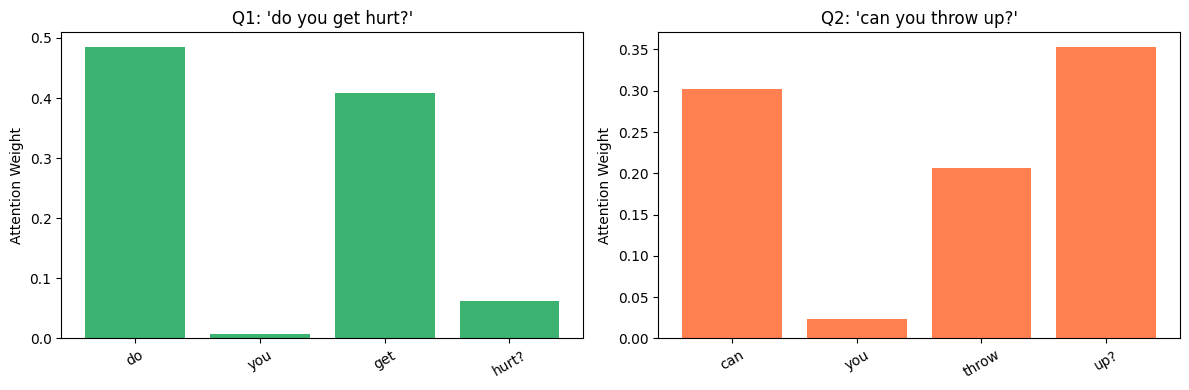

Q1 Top Word: 'do' (Weight: 0.4851)
Q2 Top Word: 'up?' (Weight: 0.3531)


In [12]:
# Select two questions with similar underlying intent/meaning
idx1, idx2 = 0, 4  # "do you get hurt?" and "can you throw up?"

q1_text = df["question"].iloc[idx1]
q2_text = df["question"].iloc[idx2]

words1 = q1_text.split()
words2 = q2_text.split()

with torch.no_grad():
    _, weights1 = model(X[idx1 : idx1 + 1])
    _, weights2 = model(X[idx2 : idx2 + 1])

w1_list = weights1[0, : len(words1)].tolist()
w2_list = weights2[0, : len(words2)].tolist()

# Plot comparison
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.bar(words1, w1_list, color="mediumseagreen")
ax1.set_title(f"Q1: '{q1_text}'")
ax1.set_ylabel("Attention Weight")
ax1.tick_params(axis="x", rotation=30)

ax2.bar(words2, w2_list, color="coral")
ax2.set_title(f"Q2: '{q2_text}'")
ax2.set_ylabel("Attention Weight")
ax2.tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

print(
    f"Q1 Top Word: '{words1[w1_list.index(max(w1_list))]}' (Weight:"
    f" {max(w1_list):.4f})"
)
print(
    f"Q2 Top Word: '{words2[w2_list.index(max(w2_list))]}' (Weight:"
    f" {max(w2_list):.4f})"
)

The model focuses on different individual words (hurt vs. throw), but these words play identical functional/semantic roles within their respective sentences (i.e., physical/biological sensations that a bot without a physical body cannot experience).

This demonstrates that attention learns to highlight semantic focal points rather than memorizing fixed sentence positions. Even when syntax or phrasing changes, attention dynamically shifts weight to the key predicate or object that determines the underlying answer category (I don't have a body.).